# Neural ODEs with mini-batch training

**Goal.** Train a neural vector field $f_\theta$ from observed trajectories using genuine PyTorch mini-batches, and understand the shapes passed into `odeint`.

We learn an **autonomous** system
$$\frac{d\mathbf z(t)}{dt}=f_\theta(\mathbf z(t)), \qquad \mathbf z(t_0)=\mathbf z_0.$$

We will (1) simulate many trajectories from a known dynamical system, (2) build a `Dataset` of **short trajectory windows**, (3) use `DataLoader` to sample independent windows in each mini-batch, (4) integrate all windows in a **single ODE solve**, and (5) evaluate on held-out initial conditions.

**Important distinction:** mini-batching means sampling *training examples* (here: trajectory windows), not approximating the integration of an individual trajectory by randomly subsampling its solver steps.

In [1]:
# Run once in Colab/Jupyter if needed:
%pip -q install torchdiffeq

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchdiffeq import odeint, odeint_adjoint
import matplotlib.pyplot as plt

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
print("Device:", DEVICE)

Device: cpu


## 1. Generate training data

Our ground truth is a two-dimensional **damped oscillator**:
$$\dot z_1=z_2,\qquad \dot z_2=-\omega^2 z_1-\gamma z_2.$$

Each initial condition produces a different trajectory. We hold out **entire trajectories** for testing, so evaluation checks generalization to new initial conditions, rather than windows of a seen trajectory.

Training trajectories: torch.Size([96, 61, 2])
Test trajectories:     torch.Size([16, 61, 2])


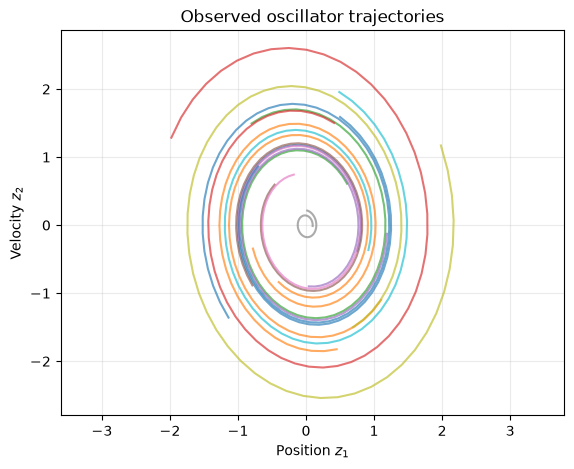

In [3]:
OMEGA = 1.3
GAMMA = 0.18
T_END = 6.0
NUM_TIMES = 61
N_TRAIN = 96
N_TEST = 16

t_grid = torch.linspace(0, T_END, NUM_TIMES, dtype=DTYPE)

class TrueDynamics(nn.Module):
    def forward(self, t, z):
        return torch.stack((z[..., 1], -OMEGA**2 * z[..., 0] - GAMMA * z[..., 1]), dim=-1)

rng = np.random.default_rng(SEED)
z0_all = torch.tensor(rng.uniform(-2, 2, size=(N_TRAIN + N_TEST, 2)), dtype=DTYPE)
with torch.no_grad():
    trajectories = odeint(TrueDynamics(), z0_all, t_grid, method="dopri5", rtol=1e-8, atol=1e-9)
    # output: [time, trajectory, coordinate]
    trajectories = trajectories.permute(1, 0, 2).contiguous()

train_traj = trajectories[:N_TRAIN]
test_traj = trajectories[N_TRAIN:]
print("Training trajectories:", train_traj.shape)
print("Test trajectories:    ", test_traj.shape)

plt.figure(figsize=(6.5, 5))
for traj in train_traj[:12]:
    plt.plot(traj[:, 0], traj[:, 1], alpha=0.65)
plt.xlabel("Position $z_1$"); plt.ylabel("Velocity $z_2$")
plt.title("Observed oscillator trajectories")
plt.axis("equal"); plt.grid(alpha=0.25); plt.show()

## 2. Mini-batch dataset of trajectory windows

A training example is a window of $L$ consecutive states:
$$\big(\mathbf z(t_j),\dots,\mathbf z(t_{j+L-1})\big).$$

Because the learned dynamics are autonomous and observations share a uniform time grid, every window can be expressed on the **same relative time vector** $[0,\Delta t,\ldots,(L-1)\Delta t]$.

A batch of size $B$ returned by `DataLoader` has shape **`[B, L, 2]`**. We pass its initial states (`[B, 2]`) to `odeint`, which integrates all $B$ independent trajectories simultaneously; the result is **`[L, B, 2]`**. The batch dimension is *not* the time dimension.

In [4]:
WINDOW_LEN = 12
BATCH_SIZE = 32

class TrajectoryWindowDataset(Dataset):
    def __init__(self, paths, window_len):
        # paths: [n_trajectories, n_times, state_dim]
        self.paths = paths
        self.window_len = window_len
        self.starts_per_trajectory = paths.size(1) - window_len + 1

    def __len__(self):
        return self.paths.size(0) * self.starts_per_trajectory

    def __getitem__(self, idx):
        traj_idx, start = divmod(idx, self.starts_per_trajectory)
        return self.paths[traj_idx, start:start + self.window_len]

train_ds = TrajectoryWindowDataset(train_traj, WINDOW_LEN)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)

batch = next(iter(train_loader))
t_window = t_grid[:WINDOW_LEN] - t_grid[0]
print("Number of windows:", len(train_ds))
print("Batch:", batch.shape, "| Initial states:", batch[:, 0, :].shape)
print("Relative time points:", t_window.shape)

Number of windows: 4800
Batch: torch.Size([32, 12, 2]) | Initial states: torch.Size([32, 2])
Relative time points: torch.Size([12])


## 3. Neural vector field

The MLP maps **state to its derivative** $f_\theta:\mathbb R^2\to\mathbb R^2$. It does *not* predict the next observation directly. The ODE solver constructs the trajectory.

`torchdiffeq` calls `forward(t, z)` with both arguments even when `t` is unused. Here `z` may contain a leading batch dimension.

In [5]:
class NeuralVectorField(nn.Module):
    def __init__(self, hidden=48):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 2),
        )

    def forward(self, t, z):
        return self.net(z)

model = NeuralVectorField().to(DEVICE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Trainable parameters: 2594


## 4. One mini-batch training step

For each sampled batch, solve
$$\widehat{\mathbf Z}_{0:L-1}=\operatorname{odeint}(f_\theta, \mathbf Z_0, \mathbf t_{0:L-1}),$$
then minimize a multi-time-point loss:
$$\mathcal L(\theta)=\frac{1}{BLd}\sum_{b=1}^{B}\sum_{j=0}^{L-1}\left\|\widehat{\mathbf z}_{b,j}-\mathbf z_{b,j}\right\|_2^2.$$

The solver sees **one time grid** shared across the batch. The default below uses a fixed-step RK4 solver to keep execution predictable. Change `USE_ADJOINT=True` to use `odeint_adjoint`, which trades additional solves for reduced differentiation memory.

In [6]:
USE_ADJOINT = False  # True: adjoint-based backpropagation
solve = odeint_adjoint if USE_ADJOINT else odeint
SOLVER_KWARGS = dict(method="rk4", options={"step_size": float(t_grid[1] - t_grid[0])})

optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
t_window_device = t_window.to(DEVICE)

def train_step(batch):
    model.train()
    batch = batch.to(DEVICE)            # [B, L, 2]
    initial_states = batch[:, 0, :]     # [B, 2]
    predictions = solve(model, initial_states, t_window_device, **SOLVER_KWARGS)
    predictions = predictions.permute(1, 0, 2)  # [B, L, 2]
    loss = nn.functional.mse_loss(predictions, batch)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return loss.item(), predictions.shape

loss, shape = train_step(batch)
print("One mini-batch loss:", round(loss, 5))
print("Predictions shape:", shape)
print("Nonzero parameter gradient:", any(p.grad is not None and p.grad.abs().sum().item() > 0 for p in model.parameters()))

One mini-batch loss: 0.47988
Predictions shape: torch.Size([32, 12, 2])
Nonzero parameter gradient: True


## 5. Training loop

Each epoch iterates over shuffled mini-batches of trajectory windows. The reported loss is weighted by batch size to handle the potentially smaller final batch.

Epoch   1/35 | train MSE = 0.035539
Epoch   5/35 | train MSE = 0.000148
Epoch  10/35 | train MSE = 0.000037
Epoch  15/35 | train MSE = 0.000017
Epoch  20/35 | train MSE = 0.000015
Epoch  25/35 | train MSE = 0.000009
Epoch  30/35 | train MSE = 0.000025
Epoch  35/35 | train MSE = 0.000017


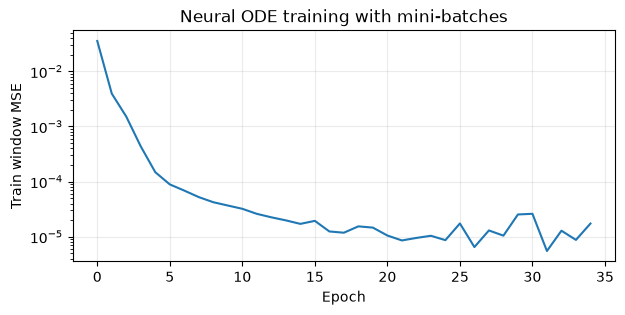

In [7]:
EPOCHS = 35  # Increase to 60–100 for a more accurate fit.
train_losses = []

for epoch in range(EPOCHS):
    total, count = 0.0, 0
    for batch in train_loader:
        loss, _ = train_step(batch)
        total += loss * len(batch)
        count += len(batch)
    epoch_loss = total / count
    train_losses.append(epoch_loss)
    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | train MSE = {epoch_loss:.6f}")

plt.figure(figsize=(7, 3))
plt.plot(train_losses)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Train window MSE")
plt.title("Neural ODE training with mini-batches"); plt.grid(alpha=0.25); plt.show()

## 6. Evaluate on unseen trajectories

During testing we **integrate across the entire time interval**, from each unseen initial condition, rather than resetting the model at every short window. This evaluates long-horizon rollout quality (errors may accumulate).

Full-rollout test MSE: 0.000016


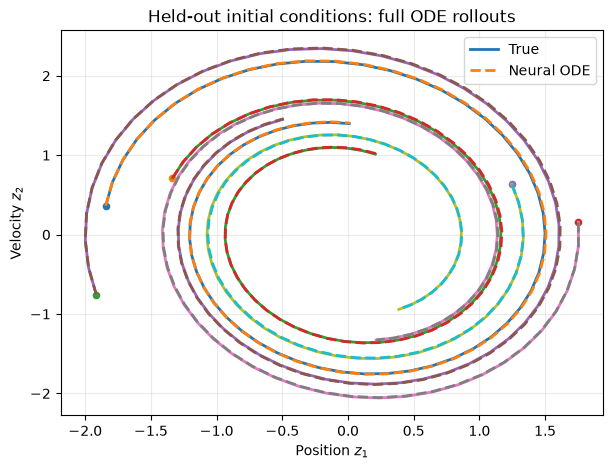

In [8]:
model.eval()
with torch.no_grad():
    z0_test = test_traj[:, 0, :].to(DEVICE)
    pred_test = odeint(model, z0_test, t_grid.to(DEVICE), method="dopri5", rtol=1e-5, atol=1e-6)
    pred_test = pred_test.permute(1, 0, 2).cpu()  # [N_test, time, 2]
    test_mse = nn.functional.mse_loss(pred_test, test_traj).item()
print(f"Full-rollout test MSE: {test_mse:.6f}")

fig, ax = plt.subplots(figsize=(7, 5))
for i in range(min(5, N_TEST)):
    ax.plot(test_traj[i, :, 0], test_traj[i, :, 1], lw=2, label="True" if i == 0 else None)
    ax.plot(pred_test[i, :, 0], pred_test[i, :, 1], '--', lw=2, label="Neural ODE" if i == 0 else None)
    ax.scatter(*test_traj[i, 0, :].tolist(), s=20)
ax.set(xlabel="Position $z_1$", ylabel="Velocity $z_2$", title="Held-out initial conditions: full ODE rollouts")
ax.legend(); ax.grid(alpha=0.25); plt.show()

## 7. Understanding the two kinds of batching

**Batch across trajectories:** if every example starts at a different $\mathbf z_0$ but uses the *same* evaluation times, one call `odeint(model, z0_batch, t)` is sufficient. This is what the notebook implements.

**Batch across time windows:** each sampled example also begins at a different *observed time*. This is valid with our **autonomous** vector field because dynamics do not depend explicitly on absolute time. For a non-autonomous field $f_\theta(t,\mathbf z)$, shifting every window to time zero is generally **incorrect**. You must preserve its absolute time (for example, group windows with identical start times, or encode absolute time into an augmented state and integrate using relative time).

**Potential experiments:** (a) vary `WINDOW_LEN` and compare short-window training loss to full-rollout error; (b) compare `odeint` and `odeint_adjoint`; (c) vary `BATCH_SIZE`; (d) replace RK4 with `dopri5`, noting the change in adaptive solver evaluations.

**Reference:** [torchdiffeq documentation](https://github.com/rtqichen/torchdiffeq).